# Exploratory Data Analysis (EDA)

This notebook focuses on understanding the dataset before training a fraud detection model. The purpose of the EDA is to inspect the data structure, identify patterns in the features, and detect any imbalance or anomalies that may affect model performance.

The main goals of this notebook are:

- Load and inspect the dataset
- Check the shape, column names, and data types
- Understand the target variable and class distribution
- Identify whether the data is imbalanced
- Detect missing values and invalid entries
- Examine the distribution of transaction features
- Compare legitimate and fraudulent transactions
- Analyze transaction amount and timing patterns
- Detect outliers and unusual behavior
- Identify relationships between variables
- Prepare the data for the next modeling stage

The key point of this EDA is that fraud detection is not just a standard classification task. Because fraudulent transactions are rare, the dataset is highly imbalanced, so we must carefully analyze the data before building a model. This notebook helps us understand how the data behaves and what challenges must be addressed during modeling.

By the end of this notebook, we should have a clear understanding of:
- the dataset structure
- the severity of class imbalance
- which features are most relevant
- whether there are suspicious patterns in fraudulent transactions
- what preprocessing and modeling decisions should follow



## 1. Data Loading
In this section, we load the dataset into a pandas DataFrame and inspect its basic structure.

The objective is to confirm that the data has been read correctly and to understand:

the number of rows and columns
the column names
the data types
the first few records
This step is important because it gives us an initial view of the dataset and helps us verify that the file path and format are correct before proceeding with deeper analysis.

In [1]:
import pandas as pd

df = pd.read_csv("../data/raw/creditcard.csv")
df.head()

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


After loading the data, we can inspect the shape and schema to confirm the dataset contents.

In [2]:
print(df.shape)

(284807, 31)


In [3]:

df.info()

<class 'pandas.DataFrame'>
RangeIndex: 284807 entries, 0 to 284806
Data columns (total 31 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   Time    284807 non-null  float64
 1   V1      284807 non-null  float64
 2   V2      284807 non-null  float64
 3   V3      284807 non-null  float64
 4   V4      284807 non-null  float64
 5   V5      284807 non-null  float64
 6   V6      284807 non-null  float64
 7   V7      284807 non-null  float64
 8   V8      284807 non-null  float64
 9   V9      284807 non-null  float64
 10  V10     284807 non-null  float64
 11  V11     284807 non-null  float64
 12  V12     284807 non-null  float64
 13  V13     284807 non-null  float64
 14  V14     284807 non-null  float64
 15  V15     284807 non-null  float64
 16  V16     284807 non-null  float64
 17  V17     284807 non-null  float64
 18  V18     284807 non-null  float64
 19  V19     284807 non-null  float64
 20  V20     284807 non-null  float64
 21  V21     284807 non-nu

This provides the first overview of the dataset and allows us to move to the next stage of analysis, where we examine the class distribution and data quality.


## 2. Dataset Overview
After loading the data, we inspect the dataset at a high level to understand its structure and basic properties.

The main purpose of this section is to confirm:

the total number of rows and columns
the data types of each feature
whether the data contains missing values
whether the feature scales are consistent
whether the dataset matches the expected fraud detection schema
This gives us a quick but essential view of the dataset before analyzing the target variable and feature distributions.

In [6]:

df.info()
df.describe()

<class 'pandas.DataFrame'>
RangeIndex: 284807 entries, 0 to 284806
Data columns (total 31 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   Time    284807 non-null  float64
 1   V1      284807 non-null  float64
 2   V2      284807 non-null  float64
 3   V3      284807 non-null  float64
 4   V4      284807 non-null  float64
 5   V5      284807 non-null  float64
 6   V6      284807 non-null  float64
 7   V7      284807 non-null  float64
 8   V8      284807 non-null  float64
 9   V9      284807 non-null  float64
 10  V10     284807 non-null  float64
 11  V11     284807 non-null  float64
 12  V12     284807 non-null  float64
 13  V13     284807 non-null  float64
 14  V14     284807 non-null  float64
 15  V15     284807 non-null  float64
 16  V16     284807 non-null  float64
 17  V17     284807 non-null  float64
 18  V18     284807 non-null  float64
 19  V19     284807 non-null  float64
 20  V20     284807 non-null  float64
 21  V21     284807 non-nu

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
count,284807.000000,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,...,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,284807.000000,284807.000000
mean,94813.859575,1.175161e-15,3.384974e-16,-1.379537e-15,2.094852e-15,1.021879e-15,1.494498e-15,-5.620335e-16,1.149614e-16,-2.414189e-15,...,1.628620e-16,-3.576577e-16,2.618565e-16,4.473914e-15,5.109395e-16,1.686100e-15,-3.661401e-16,-1.227452e-16,88.349619,0.001727
std,47488.145955,1.958696e+00,1.651309e+00,1.516255e+00,1.415869e+00,1.380247e+00,1.332271e+00,1.237094e+00,1.194353e+00,1.098632e+00,...,7.345240e-01,7.257016e-01,6.244603e-01,6.056471e-01,5.212781e-01,4.822270e-01,4.036325e-01,3.300833e-01,250.120109,0.041527
min,0.000000,-5.640751e+01,-7.271573e+01,-4.832559e+01,-5.683171e+00,-1.137433e+02,-2.616051e+01,-4.355724e+01,-7.321672e+01,-1.343407e+01,...,-3.483038e+01,-1.093314e+01,-4.480774e+01,-2.836627e+00,-1.029540e+01,-2.604551e+00,-2.256568e+01,-1.543008e+01,0.000000,0.000000
25%,54201.500000,-9.203734e-01,-5.985499e-01,-8.903648e-01,-8.486401e-01,-6.915971e-01,-7.682956e-01,-5.540759e-01,-2.086297e-01,-6.430976e-01,...,-2.283949e-01,-5.423504e-01,-1.618463e-01,-3.545861e-01,-3.171451e-01,-3.269839e-01,-7.083953e-02,-5.295979e-02,5.600000,0.000000
50%,84692.000000,1.810880e-02,6.548556e-02,1.798463e-01,-1.984653e-02,-5.433583e-02,-2.741871e-01,4.010308e-02,2.235804e-02,-5.142873e-02,...,-2.945017e-02,6.781943e-03,-1.119293e-02,4.097606e-02,1.659350e-02,-5.213911e-02,1.342146e-03,1.124383e-02,22.000000,0.000000
75%,139320.500000,1.315642e+00,8.037239e-01,1.027196e+00,7.433413e-01,6.119264e-01,3.985649e-01,5.704361e-01,3.273459e-01,5.971390e-01,...,1.863772e-01,5.285536e-01,1.476421e-01,4.395266e-01,3.507156e-01,2.409522e-01,9.104512e-02,7.827995e-02,77.165000,0.000000
max,172792.000000,2.454930e+00,2.205773e+01,9.382558e+00,1.687534e+01,3.480167e+01,7.330163e+01,1.205895e+02,2.000721e+01,1.559499e+01,...,2.720284e+01,1.050309e+01,2.252841e+01,4.584549e+00,7.519589e+00,3.517346e+00,3.161220e+01,3.384781e+01,25691.160000,1.000000


### Results:
- Dataset Shape:

    - Total rows: 284,807
    - Total columns: 31
    - Data Types: 30 columns are float64 (Time, V1-V28, Amount), 1 column is int64 (Class)
- Missing Values:
All 284,807 rows are non-null across all columns
There are no missing values in the dataset
Feature Statistics:

- The describe() output shows:

    - Time: ranges from 0 to 172,792 seconds (about 48 hours), with a mean of 94,813 seconds
    - PCA Features (V1-V28): centered around 0 with standard deviations around 1-2, indicating they have already been standardized
    - Amount: ranges from $0 to $25,691, with a mean of $88.35 and most transactions below $77
    - Class: binary target variable (0 or 1)

### Key Observations:

No missing data: The dataset is complete with no null values, so no imputation is needed.

Already scaled features: The PCA-transformed features (V1-V28) are centered near 0 with similar standard deviations, indicating they have been preprocessed.

Transaction amounts vary widely: The Amount feature has a large range ($0 to $25,691) with a right-skewed distribution (mean > median).

Time is sequential: The Time column represents seconds elapsed from the start of the dataset, ranging across a 48-hour period.


The dataset is clean and well-prepared, with no obvious data quality issues to address. We can now proceed to examine the class distribution and feature relationships.

## 3. Class Distribution
The target variable is the most important part of the dataset because it determines whether a transaction is legitimate or fraudulent. In this notebook, we examine how often each class appears in the data.

The purpose of this step is to confirm the degree of class imbalance and understand how it affects model training and evaluation.


In [7]:
df["Class"].value_counts()
df["Class"].value_counts(normalize=True)

Class
0    0.998273
1    0.001727
Name: proportion, dtype: float64

In [8]:
print(df["Class"].value_counts())
print(df["Class"].value_counts(normalize=True))

Class
0    284315
1       492
Name: count, dtype: int64
Class
0    0.998273
1    0.001727
Name: proportion, dtype: float64


### Results:
- Class 0    283,315
- Class 1        492

### Interpretation
This is an extreme class imbalance problem:

- 99.83% of transactions are legitimate (Class 0)
- Only 0.17% are fraudulent (Class 1)

This means:

    - A model that always predicts 0 would achieve 99.83% accuracy but detect zero frauds.
    - Accuracy alone is a misleading metric for this task.
    - We must use metrics such as precision, recall, F1-score, ROC-AUC, and PR-AUC instead.
    - Class imbalance must be addressed during model training through resampling, class weights, or threshold tuning.
This extreme imbalance is one of the most important findings in the dataset and will strongly influence every decision made during model development.

## 4. Missing Values Check
After inspecting the dataset structure and class distribution, we check whether the dataset contains missing or null values.

This step is important because missing data can affect model quality and must be handled appropriately before training. In many datasets, missing values require imputation or removal, but in this one we want to confirm whether that is necessary.

In [13]:
df.isnull().sum()
df.isnull().sum().sum()

np.int64(0)

### Results:
The dataset has:
- No missing values
- 0 null entries across all columns

### Interpretation:
This means the dataset is already complete and *does not require missing-value treatment before modeling*.

Since the PCA-transformed features and the other variables are already present without nulls, we can proceed directly to feature analysis and model preparation without imputation.

This is a good sign because it keeps the preprocessing stage simple and allows us to focus on the more important challenge: the extreme class imbalance.

## 5. Transaction Amount Analysis

In this section, we analyze the Amount feature to understand how transaction amounts differ between legitimate and fraudulent transactions.

This is important because fraudulent transactions often have different spending patterns compared with normal transactions. Examining the amount distribution helps us identify whether unusually large or suspicious transactions are more common in the fraud class.

In [14]:
df["Amount"].describe()
df.groupby("Class")["Amount"].describe()

,count,mean,std,min,25%,50%,75%,max
Class,,,,,,,,
0,284315.0000,88.2910,250.1051,0.0000,5.6500,22.0000,77.0500,25691.1600
1,492.0000,122.2113,256.6833,0.0000,1.0000,9.2500,105.8900,2125.8700


### Key Findings:
- Fraudulent transactions have a higher mean amount ($122.21 vs $88.29)
- But fraudulent transactions have a lower median amount ($9.25 vs $22.00)
- Fraudulent transactions have lower maximum values ($2,125.87 vs $25,691.16)
- This suggests: fraudulent transactions are typically small amounts, but some large frauds exist

### Interpretation
The Amount feature shows a difference between fraud and legitimate transactions, but the pattern is complex. It alone cannot reliably distinguish fraud from legitimate transactions, so other features will be important for the model.

## 6. Time Analysis

In [15]:
df["Time"].describe()

count   284807.0000
mean     94813.8596
std      47488.1460
min          0.0000
25%      54201.5000
50%      84692.0000
75%     139320.5000
max     172792.0000
Name: Time, dtype: float64

### Results:
- Minimum: 0 seconds
- Maximum: 172,792 seconds
- Mean: 94,813.86 seconds
- Median: 84,692 seconds

### Interpretation:
The Time column records the seconds elapsed between each transaction and the first transaction in the dataset. It spans roughly two days, which suggests the data was collected over a continuous 48-hour period.

This feature can be useful because it may reveal transaction timing patterns. For example:

fraudulent activity may occur in bursts
transactions may cluster around specific times
fraud may be more frequent in certain time windows

### Visualization:

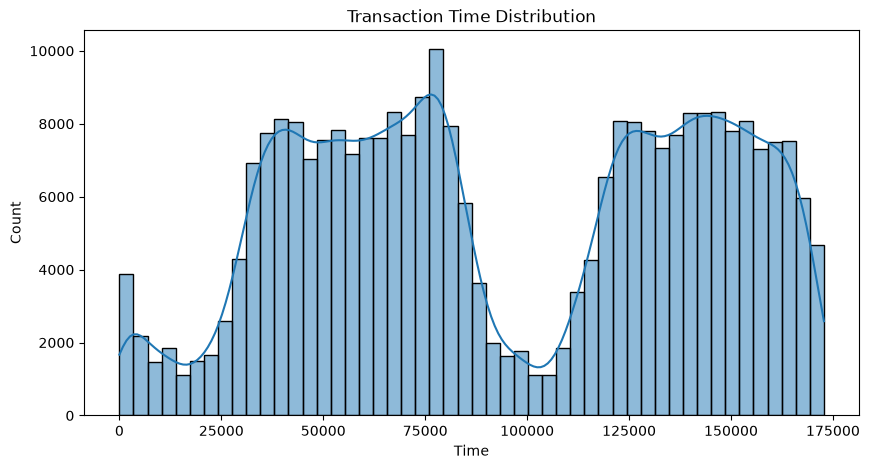

In [16]:
plt.figure(figsize=(10, 5))
sns.histplot(df["Time"], bins=50, kde=True)
plt.title("Transaction Time Distribution")
plt.show()

### Results:
The histogram shows a bimodal distribution with two distinct peaks:

- First peak around 75,000 seconds
- Second peak around 150,000 seconds
- A significant dip in the middle around 100,000-120,000 seconds

This suggests transactions cluster around two time periods during the 48-hour window, likely corresponding to two separate business days (daytime activity, with lower activity during nighttime).
### Key Findings
- Transactions are *not uniformly distributed* across time
- Activity is concentrated during certain hours (likely business/daytime hours)
- There is a clear lull between the two peaks (likely nighttime)
- This pattern is expected for real credit card data

### Interpretation: 

The Time feature captures legitimate business cycle patterns. This could help the model because fraudulent transactions might deviate from normal timing patterns, or they might follow similar patterns. This should be explored further during modeling.


## 7. Feature Distribution and Outliers

In [10]:
df.iloc[:, 1:-1].describe()

,V1,V2,V3,V4,V5,V6,V7,V8,V9,V10,...,V20,V21,V22,V23,V24,V25,V26,V27,V28,Amount
count,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,...,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,284807.000000
mean,1.175161e-15,3.384974e-16,-1.379537e-15,2.094852e-15,1.021879e-15,1.494498e-15,-5.620335e-16,1.149614e-16,-2.414189e-15,2.238554e-15,...,6.418678e-16,1.628620e-16,-3.576577e-16,2.618565e-16,4.473914e-15,5.109395e-16,1.686100e-15,-3.661401e-16,-1.227452e-16,88.349619
std,1.958696e+00,1.651309e+00,1.516255e+00,1.415869e+00,1.380247e+00,1.332271e+00,1.237094e+00,1.194353e+00,1.098632e+00,1.088850e+00,...,7.709250e-01,7.345240e-01,7.257016e-01,6.244603e-01,6.056471e-01,5.212781e-01,4.822270e-01,4.036325e-01,3.300833e-01,250.120109
min,-5.640751e+01,-7.271573e+01,-4.832559e+01,-5.683171e+00,-1.137433e+02,-2.616051e+01,-4.355724e+01,-7.321672e+01,-1.343407e+01,-2.458826e+01,...,-5.449772e+01,-3.483038e+01,-1.093314e+01,-4.480774e+01,-2.836627e+00,-1.029540e+01,-2.604551e+00,-2.256568e+01,-1.543008e+01,0.000000
25%,-9.203734e-01,-5.985499e-01,-8.903648e-01,-8.486401e-01,-6.915971e-01,-7.682956e-01,-5.540759e-01,-2.086297e-01,-6.430976e-01,-5.354257e-01,...,-2.117214e-01,-2.283949e-01,-5.423504e-01,-1.618463e-01,-3.545861e-01,-3.171451e-01,-3.269839e-01,-7.083953e-02,-5.295979e-02,5.600000
50%,1.810880e-02,6.548556e-02,1.798463e-01,-1.984653e-02,-5.433583e-02,-2.741871e-01,4.010308e-02,2.235804e-02,-5.142873e-02,-9.291738e-02,...,-6.248109e-02,-2.945017e-02,6.781943e-03,-1.119293e-02,4.097606e-02,1.659350e-02,-5.213911e-02,1.342146e-03,1.124383e-02,22.000000
75%,1.315642e+00,8.037239e-01,1.027196e+00,7.433413e-01,6.119264e-01,3.985649e-01,5.704361e-01,3.273459e-01,5.971390e-01,4.539234e-01,...,1.330408e-01,1.863772e-01,5.285536e-01,1.476421e-01,4.395266e-01,3.507156e-01,2.409522e-01,9.104512e-02,7.827995e-02,77.165000
max,2.454930e+00,2.205773e+01,9.382558e+00,1.687534e+01,3.480167e+01,7.330163e+01,1.205895e+02,2.000721e+01,1.559499e+01,2.374514e+01,...,3.942090e+01,2.720284e+01,1.050309e+01,2.252841e+01,4.584549e+00,7.519589e+00,3.517346e+00,3.161220e+01,3.384781e+01,25691.160000


This shows that the PCA-transformed features (V1 to V28) are centered around zero and have varying spread, which is consistent with standardized transformed variables.

### Key Observation: 
The features are already scaled and mostly symmetric, with some extreme values in the tails. This is common in fraud datasets and indicates that unusual transactions may stand out clearly.

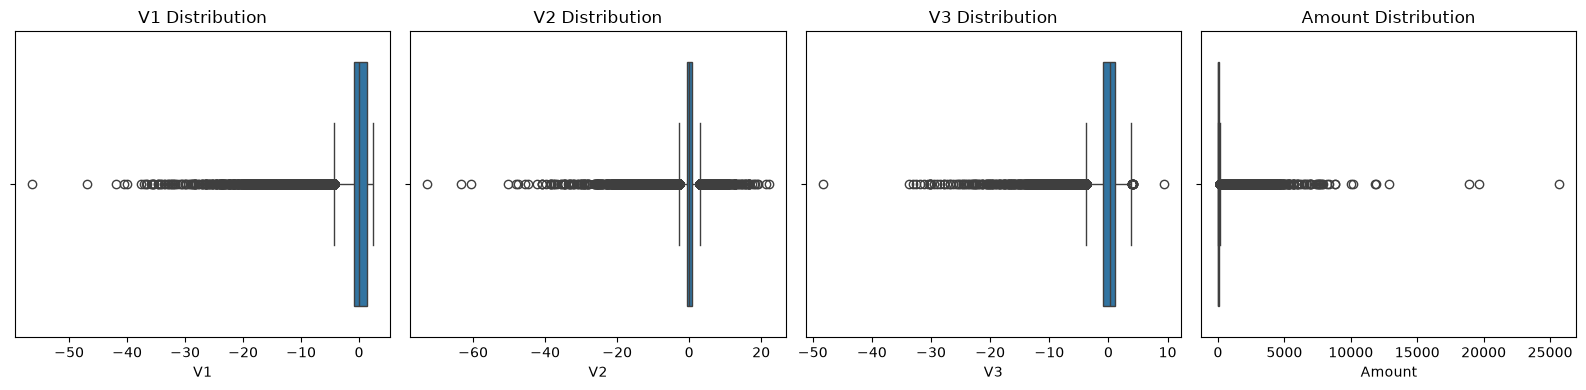

In [15]:
import matplotlib.pyplot as plt
import seaborn as sns

fig, axes = plt.subplots(1, 4, figsize=(16, 4))

for idx, col in enumerate(["V1", "V2", "V3", "Amount"]):
    sns.boxplot(x=df[col], ax=axes[idx])
    axes[idx].set_title(f"{col} Distribution")

plt.tight_layout()
plt.show()

### Interpretation
- V1, V2, and V3 show values far from the center, which indicates the presence of outliers.
- The outlier behavior is expected in fraud datasets, where unusual transactions can stand out sharply.
- Amount is clearly skewed and has a long right tail, meaning a small number of transactions are much larger than the rest.
- These extreme values may be important signals for detecting fraud.

### Key Point
The feature distributions confirm that fraudulent activity is likely associated with abnormal or rare values. This supports the idea that the model must be evaluated with metrics suited for imbalanced data and **rare event detection**.

## 8. Conclusion
At this point in the EDA, the main patterns are clear:

- The dataset is large, clean, and complete.
- The target variable is highly imbalanced:
    - Class 0: 99.83%
    - Class 1: 0.17%
- There are no missing values.
- The PCA features are centered around zero and contain outliers.
- The transaction amount distribution is highly skewed.
- The time feature shows a bimodal pattern, suggesting clustered activity across the day.
- Fraudulent transactions are likely rare and unusual compared to normal activity.

This is a classic imbalanced anomaly detection problem. The challenge is not only to train a model, but also to choose a model and evaluation strategy that can *detect rare fraudulent cases effectively*.

The next step is to start the modeling workflow:

1. split the data into train and test sets
2. choose a baseline classifier
3. handle class imbalance
4. evaluate using fraud-focused metrics

This prepares us for the next notebook: [Model Training and Evaluation](./02_model_training.ipynb).